In [25]:
import os
import time
import sys
import importlib
import logging
import pandas as pd
import lmdfitAgus
importlib.reload(lmdfitAgus)

<module 'lmdfitAgus' from '/home/amyliu/Desktop/GR/AgusDatasetBasedCompare/lmdfitAgus.py'>

In [26]:
# Environment settings
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "true"
os.environ["WANDB_MODE"] = "disabled"

logging.getLogger("codecarbon").setLevel(logging.CRITICAL)


In [27]:
# Experiment settings
sample_size = 200
group_size = 100
num_repeat = 3
text_column = "sentence"

csv_file = "financial_original.csv"

In [28]:
# Check dataset
df_data = pd.read_csv(csv_file)
print(df_data.head())
print(df_data.columns)
print(df_data.shape)

                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2
Index(['sentence', 'label'], dtype='str')
(4846, 2)


Repetition 1/3
quantiles
Q1      56
Q2      48
Q3      50
Q4      50
Q5      50
        ..
Q96     46
Q97     52
Q98     46
Q99     49
Q100    47
Name: count, Length: 100, dtype: int64
Sample Size: 200
Actual Sample Size: 200
Minimum Token Count: 6
Average Token Count: 23.29
Maximum Token Count: 52
Cleaning punctuation ...
Preparing BERT Embeddings ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Transforming Data ...
Calculating cosine similarities ...
count    19900.0000
mean         0.7033
std          0.0730
min          0.3690
25%          0.6556
50%          0.7054
75%          0.7527
max          0.9676
Name: Similarity Score, dtype: str
Mean: 0.703
Skewness: -0.163
Max Height: 5.621
Elapsed time: 4.50 seconds
0.02645 gCO2eq
Cleaning punctuation ...
Preparing BERT Embeddings ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (54 outputs left out)

Transforming Data ...
Calculating cosine similarities ...
count    19900.0000
mean         0.8299
std          0.0402
min          0.6642
25%          0.8033
50%          0.8320
75%          0.8590
max          0.9717
Name: Similarity Score, dtype: str
Mean: 0.830
Skewness: -0.284
Max Height: 10.031
Elapsed time: 5.05 seconds
0.02691 gCO2eq
Cleaning punctuation ...
Preparing BERT Embeddings ...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Transforming Data ...
Calculating cosine similarities ...
count    19900.0000
mean         0.8233
std          0.0508
min          0.5926
25%          0.7923
50%          0.8296
75%          0.8604
max          0.9485
Name: Similarity Score, dtype: str
Mean: 0.823
Skewness: -0.604
Max Height: 8.193
Elapsed time: 4.59 seconds
0.02725 gCO2eq
Model                                Mean    Skewness       Time    Emissions
--------------------------------  -------  ----------  ---------  -----------
google-bert/bert-base-uncased     0.69249    -0.11021   13.66678      0.08340
allenai/scibert_scivocab_uncased  0.76753    -0.82598   16.01143      0.08747
nlpaueb/legal-bert-base-uncased   0.87560    -0.48504   15.76091      0.08626
ahmedrachid/FinancialBERT         0.74716    -0.43551   15.47595      0.08632
Lianglab/PharmBERT-uncased        0.74659    -0.49115   15.58562      0.08637
recobo/agriculture-bert-uncased   0.83305    -0.38402   15.03849      0.08420
recobo/chemical-bert-uncased      

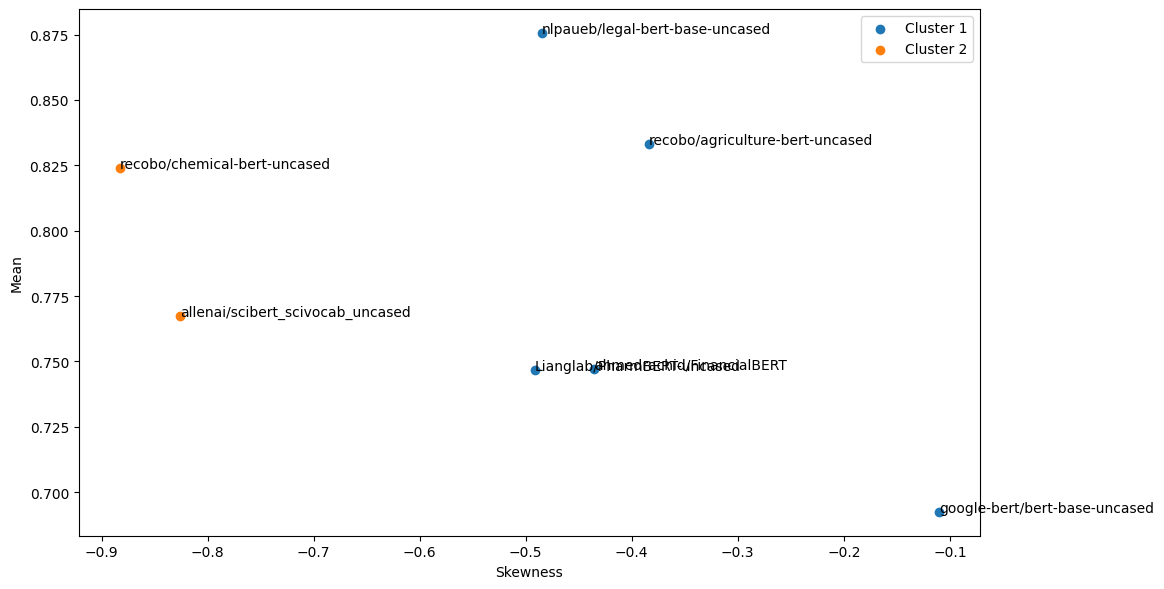

Cluster 1: more-fit
Cluster 2: less-fit
Models in the more-fit cluster: [0, 2, 3, 4, 5]
Elapsed time: 1.13 seconds
0.00443 gCO2eq


([0, 2, 3, 4, 5], [1, 6])

In [29]:
result_sizes = lmdfitAgus.running_sizes(
    csv_file=csv_file,
    sizes=[sample_size],
    x_column=text_column,
    num_repetitions=num_repeat,
    num_quantiles=group_size,
    max_token=True,
    sentence_padding=True,
    models=lmdfitAgus.models,
    batch_size=64
)

lmdfitAgus.display_lmdfit(
    result_sizes,
    mynumber=sample_size
)